In [1]:
import pandas as pd
import requests
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:

sns.set_theme(style="whitegrid", palette="muted")

def analyze_data(df, name):
    print("\n" + "="*50)
    print(f"ДАТАСЕТ: {name}")
    print("="*50)
    print("Размер таблицы:", df.shape)

    print("\nТипы данных:")
    print(df.dtypes)

    print("\nКоличество пропусков:")
    print(df.isna().sum())

    print("\nПервые 5 строк:")
    display(df.head())

    # Безопасный вывод числовых характеристик
    num_df = df.select_dtypes(include="number")
    if not num_df.empty:
        print("\nЧисловые характеристики:")
        display(num_df.describe().T)
    else:
        print("\nВ датасете нет числовых характеристик.")

    # Безопасный вывод категориальных характеристик
    cat_df = df.select_dtypes(include=["object", "category"])
    if not cat_df.empty:
        print("\nКатегориальные характеристики:")
        display(cat_df.describe().T)
    else:
        print("\nВ датасете нет категориальных характеристик.")


ДАТАСЕТ: Hotel Booking Demand
Размер таблицы: (119390, 32)

Типы данных:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
de

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Числовые характеристики:


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0



Категориальные характеристики:


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


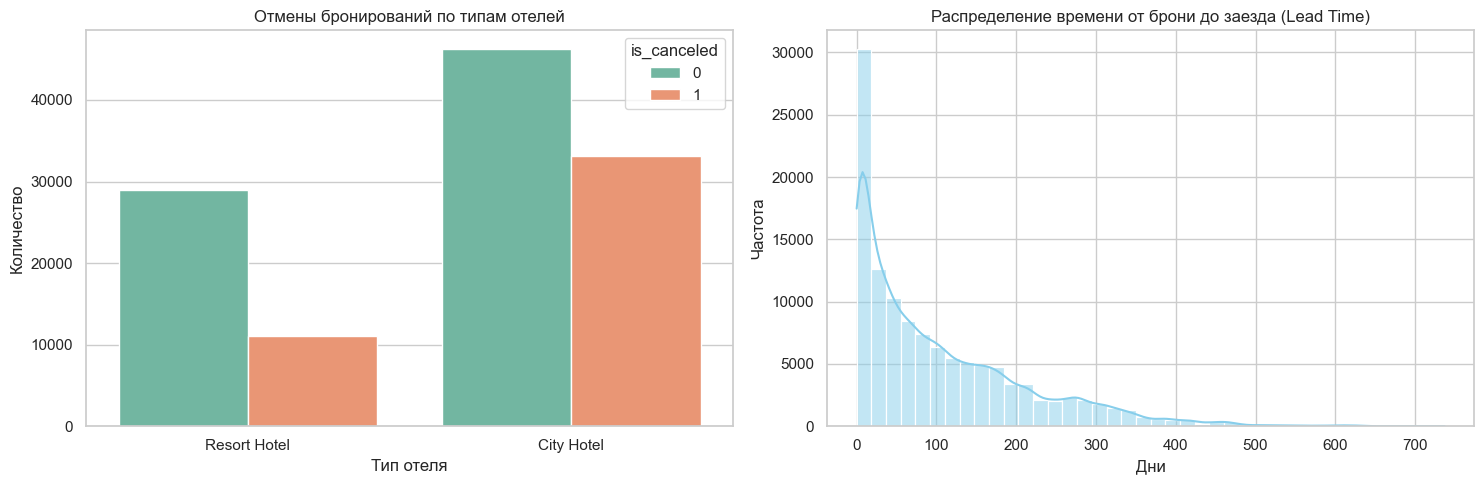

In [3]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
hotels = pd.read_csv(url)

analyze_data(hotels, "Hotel Booking Demand")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Категориальные характеристики (Тип отеля и отмены)
sns.countplot(data=hotels, x='hotel', hue='is_canceled', ax=axes[0], palette="Set2")
axes[0].set_title("Отмены бронирований по типам отелей")
axes[0].set_xlabel("Тип отеля")
axes[0].set_ylabel("Количество")

# Числовая характеристика (Lead Time - время ожидания)
sns.histplot(data=hotels, x='lead_time', bins=40, kde=True, ax=axes[1], color="skyblue")
axes[1].set_title("Распределение времени от брони до заезда (Lead Time)")
axes[1].set_xlabel("Дни")
axes[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

HTTP-код XML API: 200

ДАТАСЕТ: Eurostat XML Structure

Частичная структура XML-дерева:
<StructureSpecificData >
  <Header >
    <ID >
    <Test >
    <Prepared >
    <Sender id="ESTAT">
    <Structure dimensionAtObservation="TIME_PERIOD" structureID="STR1">
      <StructureUsage >
  <DataSet structureRef="STR1" dataScope="DataStructure" type="u:DataSetType">
    <Series geo="AL" unit="NR" c_resid="DOM" freq="M" nace_r2="I551">
      <Obs TIME_PERIOD="2017-06" OBS_VALUE="51658" OBS_FLAG="e">
      <Obs TIME_PERIOD="2017-07" OBS_VALUE="192339" OBS_FLAG="e">
      <Obs TIME_PERIOD="2017-09" OBS_VALUE="283030" OBS_FLAG="e">
      <Obs TIME_PERIOD="2017-10" OBS_VALUE="42066" OBS_FLAG="e">
      <Obs TIME_PERIOD="2017-11" OBS_VALUE="65788" OBS_FLAG="e">
    <Series geo="AT" unit="NR" c_resid="DOM" freq="M" nace_r2="I551">
      <Obs TIME_PERIOD="1990-01" OBS_VALUE="1012057">
      <Obs TIME_PERIOD="1990-02" OBS_VALUE="1454538">
      <Obs TIME_PERIOD="1990-03" OBS_VALUE="1345296">
      <Ob

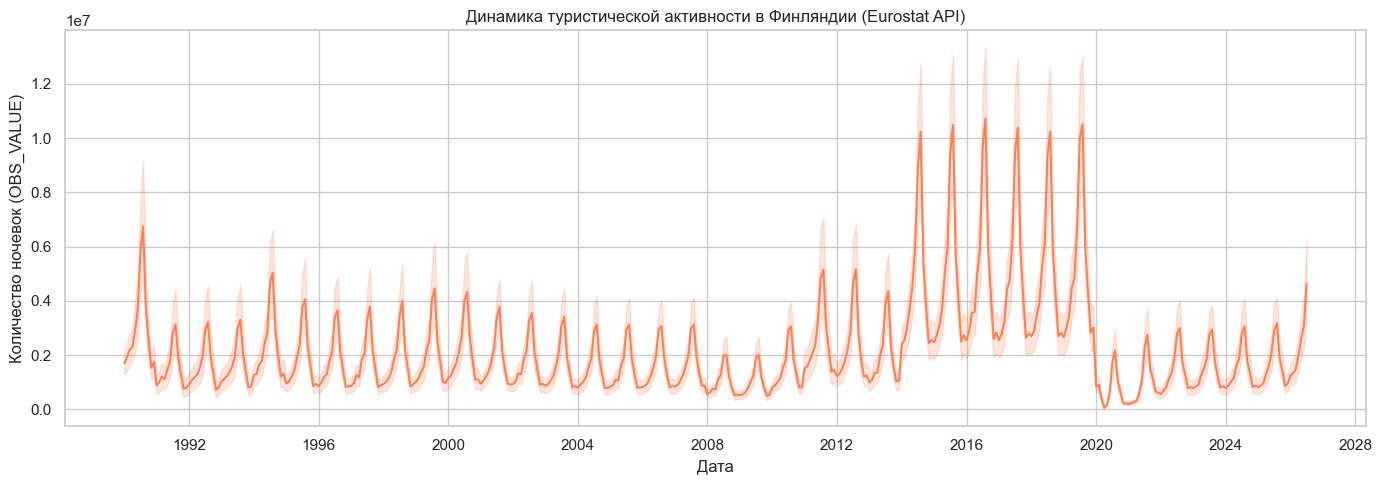

In [4]:
url = "https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/tour_occ_nim"
params = {
    "format": "SDMX_2.1_STRUCTURED",
    "geo": "FI"
}

response = requests.get(url, params=params, timeout=60)
print("HTTP-код XML API:", response.status_code)
response.raise_for_status()

root = ET.fromstring(response.content)

# 1. Сначала показываем структуру иерархического документа (XML)
def show_xml_structure(element, level=0, max_level=4):
    tag = element.tag.split("}")[-1]
    attributes = " ".join(f'{key.split("}")[-1]}="{value}"' for key, value in element.attrib.items())
    print("  " * level + f"<{tag} {attributes}>")
    if level < max_level:
        for child in list(element)[:5]: # Показываем только первые 5 дочерних элементов
            show_xml_structure(child, level + 1, max_level)

print("\n" + "="*50)
print("ДАТАСЕТ: Eurostat XML Structure")
print("="*50)
print("\nЧастичная структура XML-дерева:")
show_xml_structure(root, max_level=3) # Показываем до 3 уровня вложенности

# 2. Парсим структуру, чтобы достать данные для графика
dates, values = [], []
for elem in root.iter():
    if elem.tag.endswith('Obs'): # Ищем элементы с наблюдениями
        date = elem.attrib.get('TIME_PERIOD')
        val = elem.attrib.get('OBS_VALUE')
        if date and val:
            dates.append(date)
            values.append(float(val))

if dates and values:
    eurostat_df = pd.DataFrame({'Date': pd.to_datetime(dates), 'Value': values})
    eurostat_df = eurostat_df.sort_values('Date')
    
    plt.figure(figsize=(14, 5))
    sns.lineplot(data=eurostat_df, x='Date', y='Value', color="coral")
    plt.title("Динамика туристической активности в Финляндии (Eurostat API)")
    plt.xlabel("Дата")
    plt.ylabel("Количество ночевок (OBS_VALUE)")
    
    plt.tight_layout()
    plt.show()
else:
    print("\nНе удалось найти данные для построения графика в тегах <Obs>.")


ДАТАСЕТ: Open-Meteo Weather
Размер таблицы: (31, 5)

Типы данных:
time                   datetime64[ns]
temperature_2m_mean           float64
precipitation_sum             float64
wind_speed_10m_max            float64
temp_status                    object
dtype: object

Количество пропусков:
time                   0
temperature_2m_mean    0
precipitation_sum      0
wind_speed_10m_max     0
temp_status            0
dtype: int64

Первые 5 строк:


,time,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,temp_status
0,2025-01-01,-1.4,8.1,28.2,Мороз (ниже 0°C)
1,2025-01-02,-5.5,0.1,17.8,Мороз (ниже 0°C)
2,2025-01-03,-6.4,1.8,14.2,Мороз (ниже 0°C)
3,2025-01-04,-8.5,0.5,15.5,Мороз (ниже 0°C)
4,2025-01-05,-6.2,0.1,15.4,Мороз (ниже 0°C)



Числовые характеристики:


,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,31.0,-0.470968,3.591953,-8.5,-2.20,0.4,2.55,3.4
precipitation_sum,31.0,2.700000,3.517291,0.0,0.05,1.3,3.65,12.4
wind_speed_10m_max,31.0,25.161290,6.877339,10.8,20.15,25.5,29.75,38.3



Категориальные характеристики:


,count,unique,top,freq
temp_status,31,2,Оттепель (0°C и выше),20


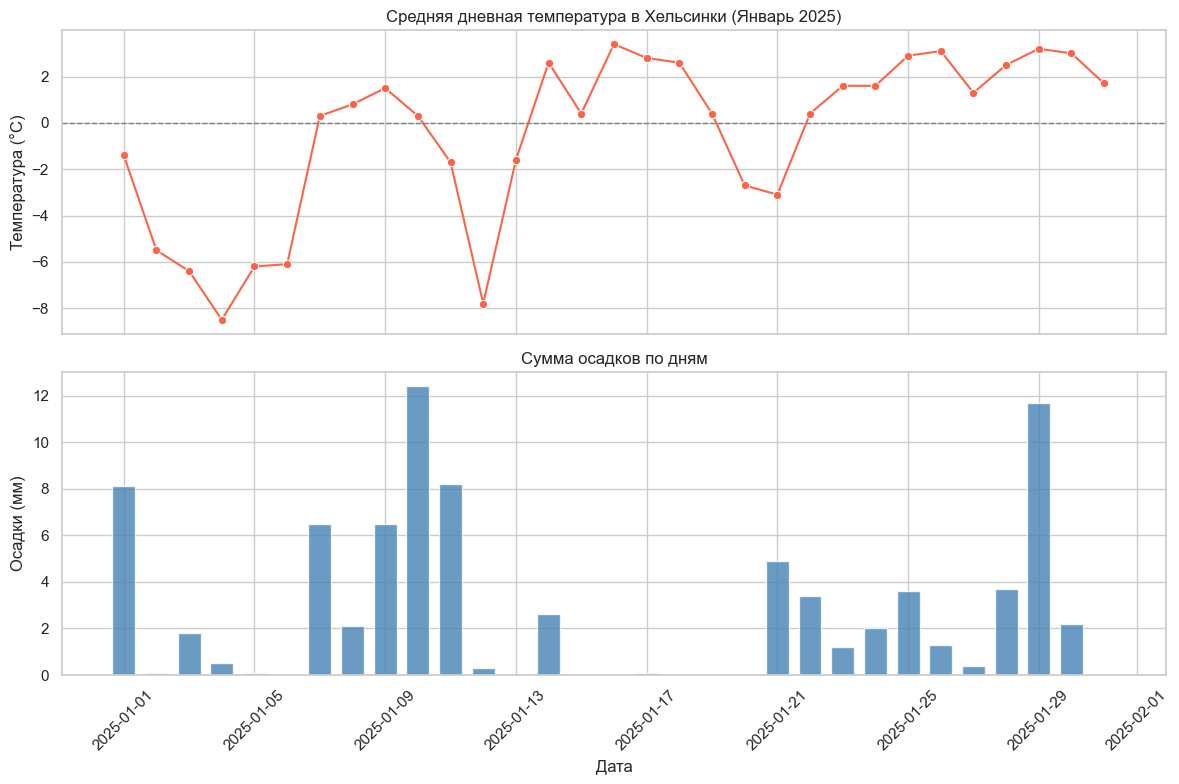

In [5]:
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 60.17,
    "longitude": 24.94,
    "start_date": "2025-01-01",
    "end_date": "2025-01-31",
    "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
    "timezone": "Europe/Helsinki"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

weather_json = response.json()
weather = pd.DataFrame(weather_json["daily"])
weather['time'] = pd.to_datetime(weather['time'])

# Добавляем категориальную характеристику для аналитического портрета
weather['temp_status'] = weather['temperature_2m_mean'].apply(
    lambda x: 'Мороз (ниже 0°C)' if x < 0 else 'Оттепель (0°C и выше)'
)

analyze_data(weather, "Open-Meteo Weather")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# График 1: Температура 
sns.lineplot(
    data=weather, x='time', y='temperature_2m_mean', 
    ax=axes[0], color='tomato', marker='o'
)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1) # Линия 0°C
axes[0].set_title("Средняя дневная температура в Хельсинки (Январь 2025)")
axes[0].set_ylabel("Температура (°C)")

# График 2: Осадки
axes[1].bar(
    weather['time'], weather['precipitation_sum'], 
    color='steelblue', alpha=0.8, width=0.7
)
axes[1].set_title("Сумма осадков по дням")
axes[1].set_ylabel("Осадки (мм)")
axes[1].set_xlabel("Дата")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


ДАТАСЕТ: TripAdvisor Reviews
Размер таблицы: (1000, 19)

Типы данных:
hotel_id                       int64
user_id                       object
title                         object
text                          object
overall                      float64
cleanliness                  float64
value                        float64
location                     float64
rooms                        float64
sleep_quality                float64
stay_year                      int64
post_date             datetime64[ns]
freq                           int64
review                        object
char                           int64
lang                          object
text_length                    int64
word_count                     int64
sentiment_category          category
dtype: object

Количество пропусков:
hotel_id              0
user_id               0
title                 0
text                  0
overall               0
cleanliness           0
value                 0
location             

,hotel_id,user_id,title,text,overall,cleanliness,value,location,rooms,sleep_quality,stay_year,post_date,freq,review,char,lang,text_length,word_count,sentiment_category
151117,140644065,2B278FAD023CF49BBC4D7C7033AAD62E,A truly wonderful Anniversary stay!,We highly recommend the Sorrento! My husband h...,5.0,5.0,5.0,5.0,5.0,5.0,2012,2012-09-18,1,A truly wonderful Anniversary stay!\nWe highly...,987,__label__en,951,167,Позитивный (4-5)
65320,127634347,DFD5A944FAC0BF7E2428CDAA7E43D7EC,Great place to stay!,This hotel was a pre-booked stop on our way so...,5.0,5.0,5.0,5.0,5.0,5.0,2012,2012-04-10,1,Great place to stay!\nThis hotel was a pre-boo...,484,__label__en,463,84,Позитивный (4-5)
120137,141332445,A4A2549CE22C2778831842BFB0415133,my experience,"Good over all, loud with renovations going on,...",3.0,3.0,3.0,3.0,3.0,2.0,2012,2012-09-26,1,"my experience\nGood over all, loud with renova...",221,__label__en,207,33,Нейтральный (3)
89594,128130600,6A7CA78C244B35BEEFFAA3DEBA6A50B2,Great Family Resort,"Stayed in a 2BR unit with our three kids (5, 8...",5.0,5.0,5.0,4.0,5.0,5.0,2012,2012-04-18,1,Great Family Resort\nStayed in a 2BR unit with...,818,__label__en,798,144,Позитивный (4-5)
177165,146684466,C8955CD48514D4D6FCC5412C97920F2E,All we needed.,"Spent 4 days last month (Nov, 2012) at this ho...",4.0,5.0,4.0,5.0,5.0,4.0,2012,2012-12-03,1,"All we needed.\nSpent 4 days last month (Nov, ...",359,__label__en,344,60,Позитивный (4-5)



Числовые характеристики:


,count,mean,std,min,25%,50%,75%,max
hotel_id,1000.0,1.352845e+08,7.115391e+06,122540714.0,1.292139e+08,134730756.0,141476116.5,147738142.0
overall,1000.0,4.135000e+00,1.042046e+00,1.0,4.000000e+00,4.0,5.0,5.0
cleanliness,1000.0,4.357000e+00,9.393793e-01,1.0,4.000000e+00,5.0,5.0,5.0
value,1000.0,4.043000e+00,1.043187e+00,1.0,3.000000e+00,4.0,5.0,5.0
location,1000.0,4.502000e+00,7.915950e-01,1.0,4.000000e+00,5.0,5.0,5.0
rooms,1000.0,4.096000e+00,1.043970e+00,1.0,4.000000e+00,4.0,5.0,5.0
sleep_quality,1000.0,4.199000e+00,1.081003e+00,1.0,4.000000e+00,5.0,5.0,5.0
stay_year,1000.0,2.012000e+03,0.000000e+00,2012.0,2.012000e+03,2012.0,2012.0,2012.0
freq,1000.0,1.000000e+00,0.000000e+00,1.0,1.000000e+00,1.0,1.0,1.0
char,1000.0,8.242500e+02,6.514771e+02,73.0,4.017500e+02,637.0,992.5,5624.0



Категориальные характеристики:


,count,unique,top,freq
user_id,1000,999,23DC8A9218CB7BF9C540FD8AC73C7788,2
title,1000,953,Great Hotel,6
text,1000,1000,We highly recommend the Sorrento! My husband h...,1
review,1000,1000,A truly wonderful Anniversary stay!\nWe highly...,1
lang,1000,1,__label__en,1000
sentiment_category,1000,3,Позитивный (4-5),797


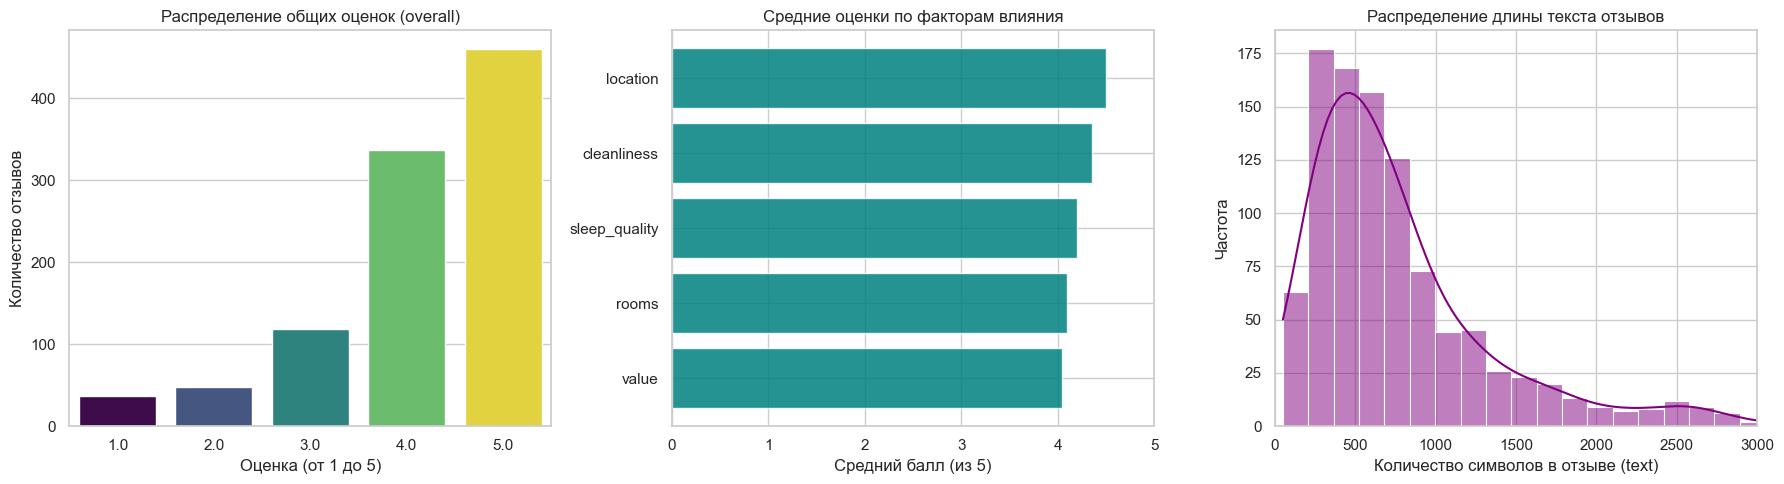

In [6]:
url = "https://huggingface.co/datasets/jniimi/tripadvisor-review-rating/resolve/main/data1000.pkl"
reviews = pd.read_pickle(url)

# 1. Извлекаем числовые и категориальные признаки из текста отзыва
reviews['text_length'] = reviews['text'].astype(str).apply(len)
reviews['word_count'] = reviews['text'].astype(str).apply(lambda x: len(x.split()))

# Добавляем понятную категорию тональности на основе общей оценки
reviews['sentiment_category'] = pd.cut(
    reviews['overall'],
    bins=[0, 2, 3, 5],
    labels=['Негативный (1-2)', 'Нейтральный (3)', 'Позитивный (4-5)']
)

analyze_data(reviews, "TripAdvisor Reviews")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Распределение общих оценок
sns.countplot(
    data=reviews, x='overall', hue='overall', 
    ax=axes[0], palette="viridis", legend=False
)
axes[0].set_title("Распределение общих оценок (overall)")
axes[0].set_xlabel("Оценка (от 1 до 5)")
axes[0].set_ylabel("Количество отзывов")

# График 2: Факторы влияния (средние оценки по критериям)
factor_cols = ['cleanliness', 'value', 'location', 'rooms', 'sleep_quality']
available_factors = [c for c in factor_cols if c in reviews.columns]
factor_means = reviews[available_factors].mean().sort_values()

axes[1].barh(factor_means.index, factor_means.values, color='teal', alpha=0.85)
axes[1].set_xlim(0, 5)
axes[1].set_title("Средние оценки по факторам влияния")
axes[1].set_xlabel("Средний балл (из 5)")

# График 3: Распределение длины текста отзывов 
sns.histplot(
    data=reviews, x='text_length', bins=35, 
    ax=axes[2], color="purple", kde=True
)
axes[2].set_xlim(0, 3000) # Ограничиваем экстремально длинные выбросы для наглядности
axes[2].set_title("Распределение длины текста отзывов")
axes[2].set_xlabel("Количество символов в отзыве (text)")
axes[2].set_ylabel("Частота")

plt.tight_layout()
plt.show()